# COU 07506 Digital Signal Processing - Week 01: Setting Up the DSP Laboratory
Name: Ansila Apolinari Mariwa

Registration No: 240242433860

Class: BEng24COE

Group: 3

Date: 24/11/2026


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

## Pre-lab
Three devices I used today that contain DSP:

1. Smartphone: processes my voice (audio signal)
2. Earphones: processes digital music/audio
3. Wi-Fi router: processes radio signals

## Task 1.1 - Elementary sequences

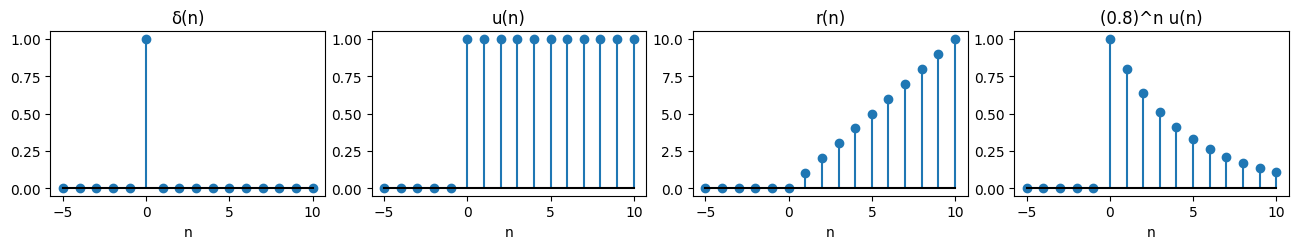

In [2]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)   # unit impulse
step  = (n >= 0).astype(float)   # unit step
ramp  = n * step                 # unit ramp
expo  = 0.8**n * step            # real exponential

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                        ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title); ax.set_xlabel("n")
plt.tight_layout(); plt.show()

## Task 1.2 - Change the parameters

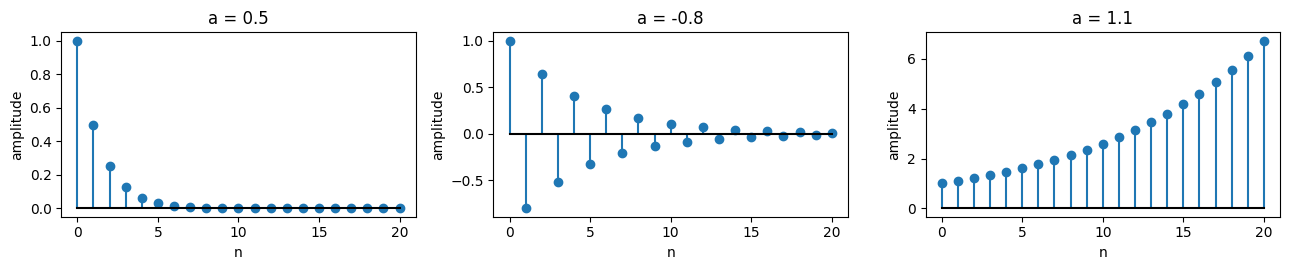

In [3]:
n = np.arange(0, 21)
fig, axes = plt.subplots(1, 3, figsize=(13, 2.8))
for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    ax.stem(n, a**n, basefmt="k-")
    ax.set_title(f"a = {a}"); ax.set_xlabel("n"); ax.set_ylabel("amplitude")
plt.tight_layout(); plt.show()

for a=0.5 it decays smoothly to zero

for a=-0.8 it decays to zero but flips sign each step

for a=1.1  it grows bigger and bigger

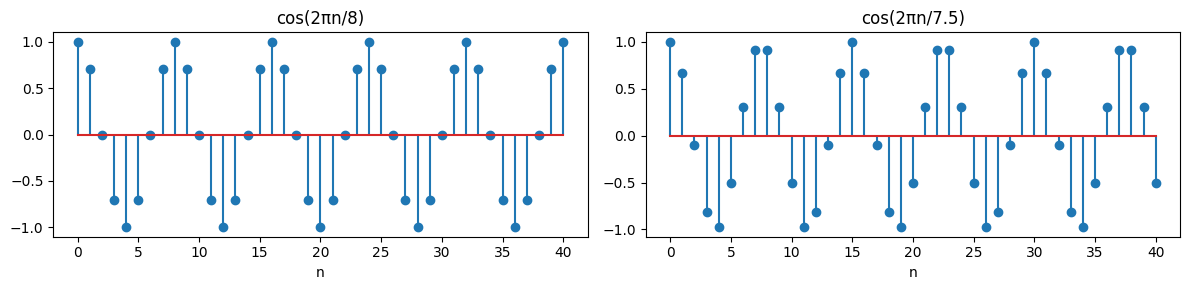

In [4]:
n = np.arange(0, 41)
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
axes[0].stem(n, np.cos(2*np.pi*n/8));   axes[0].set_title("cos(2πn/8)")
axes[1].stem(n, np.cos(2*np.pi*n/7.5)); axes[1].set_title("cos(2πn/7.5)")
for ax in axes: ax.set_xlabel("n")
plt.tight_layout(); plt.show()

cos(2*3.14n/8) repeats exactly

## Task 1.3 - Working with audio

fs = 48000 Hz, duration = 3.26 s, samples = 156672


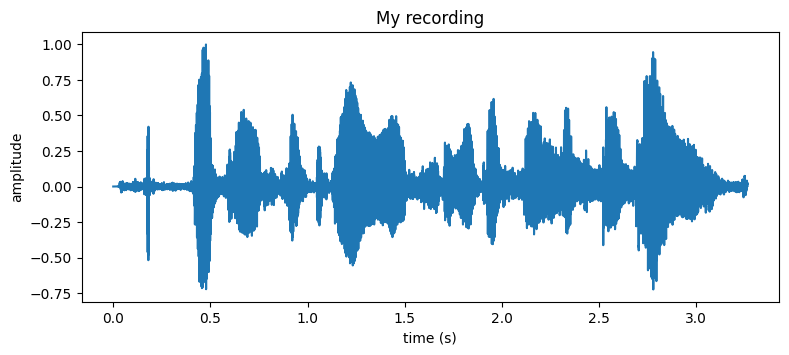

In [9]:
import os
fname = "Dsp.wav.wav"
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:
        x = x.mean(axis=1)        # stereo -> mono
    x = x / np.max(np.abs(x))     # normalise to [-1, 1]
else:                              # fallback test signal
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)
t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")
plt.plot(t, x); plt.xlabel("time (s)"); plt.ylabel("amplitude")
plt.title("My recording"); plt.show()

In [10]:
from IPython.display import Audio
Audio(x, rate=fs)

### Observation
My voice recording was read from my_voice.wav. The sampling rate is fs = 48000 Hz,
the duration is 3.26 s and it contains 156672 samples. This agrees with
samples = fs × duration (48000 × 3.26 ≈ 156672). The waveform plot shows
 bursts of larger amplitude where I was
speaking and nearly flat sections where I was silent. The amplitude is between
-1 and 1 because I normalised the signal. When I played it back, I could hear
my voice clearly.